# EcoVision — Inteligência Artificial & Machine Learning
## Previsão de eventos de precipitação extrema em São Paulo (2020–2025)

**Objetivo:** construir um classificador supervisionado que estime se uma janela de 24 horas terá precipitação acumulada extrema, usando observações meteorológicas reais do INMET.

> **Limite de interpretação:** o modelo classifica precipitação extrema, não prevê diretamente alagamentos ou enchentes. Para prever inundação seriam necessários dados de drenagem, topografia, rios, impermeabilização e registros georreferenciados de ocorrências.

**Fonte primária:** INMET — dados históricos de estações meteorológicas automáticas (CSV).  
**Recorte:** estação(ões) automática(s) localizadas no município de São Paulo, de 01/01/2020 a 31/12/2025.

### Definição operacional do alvo
`chuva_extrema_24h = 1` quando a precipitação acumulada nas próximas 24 horas for **igual ou superior a 50 mm**; caso contrário, `0`. O limiar é uma escolha operacional para este estudo e deve ser explicitado no relatório — não é um alerta oficial do INMET/Defesa Civil.

### Como executar
1. Baixe os CSVs anuais do INMET para a(s) estação(ões) de São Paulo e coloque-os em `dados/inmet/`.
2. Execute as células em ordem.
3. Confira as colunas e a cobertura temporal impressas na etapa de leitura.
4. Não interprete ausência de registro como chuva zero.


In [ ]:
from google.colab import files
files.download("/content/EcoVision_GitHub.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--------------------

In [ ]:
# ============================================================================
# ECOVISION - ETAPA 1: preparação e construção da base de dados meteorológicos
# LEITURA DOS CSVs ANUAIS DO INMET E CONSTRUCAO DA BASE DIARIA
# ============================================================================
#
# Periodo:
#   2016 a 2025
#
# Tratamentos:
#   - Detecta automaticamente a linha do cabecalho.
#   - Le arquivos separados por ponto e virgula.
#   - Interpreta datas em formatos diferentes.
#   - Interpreta horas UTC.
#   - Converte UTC para America/Sao_Paulo.
#   - Converte valores decimais com virgula.
#   - Trata -9999 como dado ausente.
#   - Agrega variaveis meteorologicas por dia local.
#   - Exige pelo menos 18 horas validas por variavel.
#   - Cria classe_alvo para o dia seguinte (D+1), uma unica vez.
# ============================================================================

import os
import re
import glob
import unicodedata
import warnings
import numpy as np
import pandas as pd
from pathlib import Path

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# 1. CONFIGURACOES
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# 1. CONFIGURACOES E CAMINHOS PORTAVEIS
# ---------------------------------------------------------------------------

ANO_INICIO = 2016
ANO_FIM = 2025

FUSO_LOCAL = "America/Sao_Paulo"
MIN_HORAS_VALIDAS = 18


# ---------------------------------------------------------------------------
# LOCALIZAR AUTOMATICAMENTE A PASTA DO PROJETO
# ---------------------------------------------------------------------------

def localizar_raiz_projeto():

    candidatos = []
    candidatos.append(Path("/content/EcoVision"))
    atual = Path.cwd().resolve()

    candidatos.extend([atual] + list(atual.parents))

    for pasta in candidatos:

        if not pasta.is_dir():
            continue

        if (
            (pasta / ".git").exists()
            or (pasta / "RELATORIO_ML.md").exists()
            or (
                (pasta / "ml").is_dir()
                and (pasta / "dados").is_dir()
            )
        ):
            return pasta

    return Path.cwd().resolve()


PASTA_PROJETO = localizar_raiz_projeto()


# ---------------------------------------------------------------------------
# LOCALIZAR OS CSVs DO INMET
# ---------------------------------------------------------------------------

PASTAS_POSSIVEIS = [

    PASTA_PROJETO / "dados" / "inmet",

    PASTA_PROJETO / "dados",

    Path("/content/dados"),
]

PASTA_INMET = None

for pasta in PASTAS_POSSIVEIS:

    if pasta.is_dir():

        arquivos_csv = (
            list(pasta.glob("*.csv"))
            + list(pasta.glob("*.CSV"))
        )

        if arquivos_csv:

            PASTA_INMET = pasta
            break


if PASTA_INMET is None:

    raise FileNotFoundError(
        "Nenhuma pasta com CSVs do INMET foi encontrada.\n"
        "Coloque os arquivos em: dados/inmet/\n"
        f"Raiz do projeto identificada: {PASTA_PROJETO}"
    )


# ---------------------------------------------------------------------------
# DEFINIR PASTA DE SAIDA
# ---------------------------------------------------------------------------

PASTA_SAIDA_BASE = (
    PASTA_PROJETO
    / "bases_processadas"
    / "saida_ecovision"
)

PASTA_SAIDA_BASE.mkdir(
    parents=True,
    exist_ok=True
)

ARQUIVO_BASE_DIARIA = (
    PASTA_SAIDA_BASE
    / "base_diaria_ecovision.csv"
)


print("=" * 80)
print("ECOVISION - CONSTRUCAO DA BASE DIARIA")
print("=" * 80)

print("\nAMBIENTE IDENTIFICADO:")
print("Raiz do projeto:", PASTA_PROJETO)
print("Pasta dos CSVs:", PASTA_INMET)
print("Pasta de saida:", PASTA_SAIDA_BASE)

print("\nPeriodo:", ANO_INICIO, "a", ANO_FIM)


# ---------------------------------------------------------------------------
# 2. FUNCOES AUXILIARES
# ---------------------------------------------------------------------------


def normalizar_texto(texto):
    """Remove acentos, padroniza maiusculas e espacos."""

    texto = str(texto).strip().upper()

    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        caractere for caractere in texto if not unicodedata.combining(caractere)
    )

    texto = re.sub(r"\s+", " ", texto)

    return texto


def localizar_cabecalho(caminho):
    """
    Procura a linha que contem os campos DATA e HORA.
    Os arquivos do INMET possuem metadados antes do cabecalho.
    """

    with open(caminho, "r", encoding="latin1", errors="replace") as arquivo:

        for indice, linha in enumerate(arquivo):

            linha_normalizada = normalizar_texto(linha)

            if "DATA" in linha_normalizada and "HORA" in linha_normalizada:
                return indice

    raise ValueError(f"Nao foi possivel localizar o cabecalho em: {caminho}")


def localizar_coluna(colunas, termos):
    """
    Localiza uma coluna usando todos os termos informados.
    Retorna o nome original da coluna.
    """

    for coluna in colunas:

        nome = normalizar_texto(coluna)

        if all(normalizar_texto(termo) in nome for termo in termos):
            return coluna

    return None


def converter_numero(serie):
    """
    Converte numeros do INMET:
    - virgula decimal para ponto;
    - valores vazios para NaN;
    - -9999 para NaN;
    - valores como ,8 para 0.8.
    """

    valores = (
        serie.astype("string")
        .str.strip()
        .str.replace('"', "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    valores = valores.replace(
        {
            "": pd.NA,
            " ": pd.NA,
            "-9999": pd.NA,
            "-9999.0": pd.NA,
            "NaN": pd.NA,
            "nan": pd.NA,
            "None": pd.NA,
        }
    )

    valores = valores.str.replace(r"^(\.)", "0.", regex=True)

    valores = valores.str.replace(r"^(-)\.", r"-0.", regex=True)

    resultado = pd.to_numeric(valores, errors="coerce")

    resultado = resultado.replace([-9999, -9999.0], np.nan)

    return resultado


def converter_data(serie):
    """
    Aceita datas como:
    2015-01-01
    2019/01/01
    01/01/2020
    """

    texto = serie.astype("string").str.strip()

    try:
        datas = pd.to_datetime(texto, format="mixed", dayfirst=True, errors="coerce")
    except (TypeError, ValueError):
        datas = pd.to_datetime(texto, dayfirst=True, errors="coerce")

    return datas.dt.normalize()


def converter_hora_utc(serie):
    """
    Aceita formatos:
    00:00
    0000 UTC
    0000
    23:00
    """

    texto = serie.astype("string").str.strip().str.upper()

    texto = texto.str.replace("UTC", "", regex=False).str.strip()

    partes = texto.str.extract(r"^\s*(\d{1,2}):?(\d{2})")

    hora = pd.to_numeric(partes[0], errors="coerce")

    minuto = pd.to_numeric(partes[1], errors="coerce")

    valido = hora.between(0, 23) & minuto.between(0, 59)

    resultado = pd.Series(pd.NA, index=serie.index, dtype="string")

    resultado.loc[valido] = (
        hora.loc[valido].astype(int).astype(str).str.zfill(2)
        + ":"
        + minuto.loc[valido].astype(int).astype(str).str.zfill(2)
    )

    return resultado


# ---------------------------------------------------------------------------
# 3. LOCALIZAR ARQUIVOS ANUAIS
# ---------------------------------------------------------------------------

arquivos = sorted(
    list(PASTA_INMET.glob("*.csv"))
    + list(PASTA_INMET.glob("*.CSV"))
)

if not arquivos:

    raise FileNotFoundError(
        f"Nenhum CSV encontrado em: {PASTA_INMET}"
    )


arquivos_por_ano = {}

for caminho in arquivos:

    nome = caminho.name

    correspondencia = re.search(
        r"_(\d{2}-\d{2}-(20\d{2}))_A_",
        nome,
        flags=re.IGNORECASE
    )

    if correspondencia:

        ano = int(correspondencia.group(2))

        if ANO_INICIO <= ano <= ANO_FIM:

            # Impede que um arquivo sobrescreva outro
            # silenciosamente para o mesmo ano.

            if ano in arquivos_por_ano:

                raise ValueError(
                    f"Mais de um arquivo encontrado para {ano}:\n"
                    f"- {arquivos_por_ano[ano].name}\n"
                    f"- {caminho.name}\n"
                    "Verifique se os arquivos pertencem a mesma estacao A701."
                )

            arquivos_por_ano[ano] = caminho


anos_esperados = list(range(ANO_INICIO, ANO_FIM + 1))

anos_encontrados = sorted(arquivos_por_ano.keys())

anos_faltantes = sorted(
    set(anos_esperados) - set(anos_encontrados)
)


print("\nARQUIVOS LOCALIZADOS:")

for ano in anos_encontrados:

    print(f"{ano}: {arquivos_por_ano[ano].name}")


if anos_faltantes:

    raise FileNotFoundError(
        "Arquivos anuais ausentes: "
        + ", ".join(map(str, anos_faltantes))
        + f"\nPasta analisada: {PASTA_INMET}"
    )


print("\nTotal de arquivos:", len(arquivos_por_ano))

print("Todos os anos de 2016 a 2025 foram localizados.")


# ---------------------------------------------------------------------------
# 4. DEFINICAO DAS COLUNAS METEOROLOGICAS
# ---------------------------------------------------------------------------

# Os nomes podem variar ligeiramente entre os anos.
# A localizacao usa trechos dos nomes, nao depende de acentos.


def mapear_colunas(colunas):

    mapa = {}

    mapa["data"] = localizar_coluna(colunas, ["DATA"])

    mapa["hora"] = localizar_coluna(colunas, ["HORA"])

    mapa["precipitacao"] = localizar_coluna(colunas, ["PRECIPITACAO TOTAL", "HORARIO"])

    mapa["temperatura"] = localizar_coluna(
        colunas, ["TEMPERATURA DO AR", "BULBO SECO", "HORARIA"]
    )

    mapa["umidade"] = localizar_coluna(colunas, ["UMIDADE RELATIVA DO AR", "HORARIA"])

    mapa["rajada"] = localizar_coluna(colunas, ["VENTO", "RAJADA MAXIMA"])

    mapa["vento"] = localizar_coluna(colunas, ["VENTO", "VELOCIDADE HORARIA"])

    mapa["pressao"] = localizar_coluna(
        colunas, ["PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO", "HORARIA"]
    )

    obrigatorias = [
        "data",
        "hora",
        "precipitacao",
        "temperatura",
        "umidade",
        "rajada",
        "vento",
        "pressao",
    ]

    ausentes = [campo for campo in obrigatorias if mapa.get(campo) is None]

    if ausentes:

        raise ValueError(
            "Colunas meteorologicas nao identificadas: "
            + ", ".join(ausentes)
            + "\nColunas encontradas: "
            + str(list(colunas))
        )

    return mapa


# ---------------------------------------------------------------------------
# 5. LEITURA E PADRONIZACAO DOS ARQUIVOS
# ---------------------------------------------------------------------------

partes_horarias = []

auditoria_arquivos = []

for ano, caminho in sorted(arquivos_por_ano.items()):

    print("\n" + "-" * 80)
    print("PROCESSANDO:", ano)
    print(os.path.basename(caminho))

    indice_cabecalho = localizar_cabecalho(caminho)

    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=indice_cabecalho,
        encoding="latin1",
        dtype="string",
        low_memory=False,
    )

    # Limpar nomes de colunas.

    df.columns = [str(coluna).replace("\ufeff", "").strip() for coluna in df.columns]

    # Remover colunas totalmente vazias.

    df = df.dropna(axis=1, how="all")

    mapa = mapear_colunas(df.columns)

    print("Cabecalho identificado na linha:", indice_cabecalho + 1)
    print("Registros lidos:", len(df))

    # Data e hora.

    data = converter_data(df[mapa["data"]])

    hora = converter_hora_utc(df[mapa["hora"]])

    data_hora = data.dt.strftime("%Y-%m-%d") + " " + hora

    timestamp_utc = pd.to_datetime(
        data_hora, format="%Y-%m-%d %H:%M", errors="coerce", utc=True
    )

    # Converter para o horario local.
    # O pandas considera automaticamente o historico de horario de verao.

    timestamp_local = timestamp_utc.dt.tz_convert(FUSO_LOCAL)

    horario_valido = timestamp_local.notna()

    dados = pd.DataFrame(
        {
            "timestamp_utc": timestamp_utc,
            "timestamp_local": timestamp_local,
            "precipitacao_mm": converter_numero(df[mapa["precipitacao"]]),
            "temperatura_c": converter_numero(df[mapa["temperatura"]]),
            "umidade_pct": converter_numero(df[mapa["umidade"]]),
            "rajada_ms": converter_numero(df[mapa["rajada"]]),
            "vento_ms": converter_numero(df[mapa["vento"]]),
            "pressao_mb": converter_numero(df[mapa["pressao"]]),
        }
    )

    dados = dados.loc[horario_valido].copy()

    # Remover valores fisicamente impossiveis ou sentinelas residuais.

    dados.loc[dados["precipitacao_mm"] < 0, "precipitacao_mm"] = np.nan

    dados.loc[~dados["temperatura_c"].between(-10, 55), "temperatura_c"] = np.nan

    dados.loc[~dados["umidade_pct"].between(0, 100), "umidade_pct"] = np.nan

    dados.loc[dados["rajada_ms"] < 0, "rajada_ms"] = np.nan

    dados.loc[dados["vento_ms"] < 0, "vento_ms"] = np.nan

    dados.loc[dados["pressao_mb"] <= 0, "pressao_mb"] = np.nan

    # Data local usada para agregacao diaria.

    dados["data"] = dados["timestamp_local"].dt.strftime("%Y-%m-%d")

    dados["data"] = pd.to_datetime(dados["data"], errors="coerce")

    # Converter vento de m/s para km/h.

    dados["rajada_kmh"] = dados["rajada_ms"] * 3.6

    dados["vento_kmh"] = dados["vento_ms"] * 3.6

    # Auditoria do arquivo.

    auditoria_arquivos.append(
        {
            "ano_arquivo": ano,
            "linhas_originais": len(df),
            "linhas_com_timestamp_valido": len(dados),
            "timestamps_invalidos": int(timestamp_local.isna().sum()),
            "primeiro_horario_local": (dados["timestamp_local"].min()),
            "ultimo_horario_local": (dados["timestamp_local"].max()),
            "duplicidades_timestamp": int(dados["timestamp_utc"].duplicated().sum()),
        }
    )

    partes_horarias.append(dados)

    print("Registros com horario valido:", len(dados))
    print("Primeiro horario local:", dados["timestamp_local"].min())
    print("Ultimo horario local:", dados["timestamp_local"].max())


# ---------------------------------------------------------------------------
# 6. CONSOLIDACAO HORARIA
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("CONSOLIDACAO DOS DADOS HORARIOS")
print("=" * 80)

horaria = pd.concat(partes_horarias, ignore_index=True)

horaria = horaria.sort_values("timestamp_utc").reset_index(drop=True)

duplicados = horaria["timestamp_utc"].duplicated(keep=False)

print("Registros horarios consolidados:", len(horaria))
print("Timestamps duplicados:", int(duplicados.sum()))

if duplicados.any():

    print(
        "ATENCAO: duplicidades encontradas. "
        "Sera mantido o primeiro registro de cada timestamp UTC."
    )

    horaria = horaria.drop_duplicates(subset="timestamp_utc", keep="first").copy()

# Auditoria horaria.

auditoria_arquivos = pd.DataFrame(auditoria_arquivos)

auditoria_arquivos.to_csv(
    os.path.join(PASTA_SAIDA_BASE, "auditoria_arquivos_inmet.csv"), index=False
)

print("\nPeriodo horario local:")
print(horaria["timestamp_local"].min())
print(horaria["timestamp_local"].max())


# ---------------------------------------------------------------------------
# 7. AGREGACAO DIARIA NO HORARIO DE SAO PAULO
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("AGREGACAO DIARIA")
print("=" * 80)

# Cada linha horaria ja esta associada a data local.
# Assim, a chuva e as demais variaveis sao agregadas pelo dia civil local.

grupo = horaria.groupby("data", sort=True)

diaria = pd.DataFrame(index=grupo.size().index)

diaria.index.name = "data"

# Contagem de observacoes validas por variavel.

diaria["chuva_horas_validas"] = grupo["precipitacao_mm"].count()

diaria["temperatura_horas_validas"] = grupo["temperatura_c"].count()

diaria["umidade_horas_validas"] = grupo["umidade_pct"].count()

diaria["rajada_horas_validas"] = grupo["rajada_kmh"].count()

diaria["vento_horas_validas"] = grupo["vento_kmh"].count()

diaria["pressao_horas_validas"] = grupo["pressao_mb"].count()

# Precipitacao diaria.

diaria["chuva_dia_mm"] = grupo["precipitacao_mm"].sum(min_count=1)

diaria["chuva_max_horaria_mm"] = grupo["precipitacao_mm"].max()

diaria["chuva_media_horaria_mm"] = grupo["precipitacao_mm"].mean()

# Temperatura.

diaria["temperatura_media"] = grupo["temperatura_c"].mean()

diaria["temperatura_minima"] = grupo["temperatura_c"].min()

diaria["temperatura_maxima"] = grupo["temperatura_c"].max()

# Umidade.

diaria["umidade_media"] = grupo["umidade_pct"].mean()

diaria["umidade_minima"] = grupo["umidade_pct"].min()

diaria["umidade_maxima"] = grupo["umidade_pct"].max()

# Vento.

diaria["rajada_maxima_kmh"] = grupo["rajada_kmh"].max()

diaria["vento_medio_kmh"] = grupo["vento_kmh"].mean()

diaria["vento_maximo_kmh"] = grupo["vento_kmh"].max()

# Pressao atmosferica.

diaria["pressao_media"] = grupo["pressao_mb"].mean()

diaria["pressao_minima"] = grupo["pressao_mb"].min()

diaria["pressao_maxima"] = grupo["pressao_mb"].max()

# Quantidade de registros horarios recebidos no dia.
# Pode variar por horario de verao e limites dos arquivos.

diaria["registros_horarios"] = grupo.size()


# ---------------------------------------------------------------------------
# 8. GRADE DIARIA CONTINUA
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("GRADE DIARIA E QUALIDADE")
print("=" * 80)

calendario = pd.date_range(
    start=f"{ANO_INICIO}-01-01", end=f"{ANO_FIM}-12-31", freq="D"
)

diaria.index = pd.to_datetime(diaria.index)

diaria = diaria.reindex(calendario)

diaria.index.name = "data"

diaria["data"] = diaria.index

colunas_contagem = [
    "chuva_horas_validas",
    "temperatura_horas_validas",
    "umidade_horas_validas",
    "rajada_horas_validas",
    "vento_horas_validas",
    "pressao_horas_validas",
    "registros_horarios",
]

for coluna in colunas_contagem:

    diaria[coluna] = diaria[coluna].fillna(0).astype(int)

# Aplicar o minimo de 18 horas validas separadamente por variavel.

regras_qualidade = {
    "chuva_horas_validas": [
        "chuva_dia_mm",
        "chuva_max_horaria_mm",
        "chuva_media_horaria_mm",
    ],
    "temperatura_horas_validas": [
        "temperatura_media",
        "temperatura_minima",
        "temperatura_maxima",
    ],
    "umidade_horas_validas": ["umidade_media", "umidade_minima", "umidade_maxima"],
    "rajada_horas_validas": ["rajada_maxima_kmh"],
    "vento_horas_validas": ["vento_medio_kmh", "vento_maximo_kmh"],
    "pressao_horas_validas": ["pressao_media", "pressao_minima", "pressao_maxima"],
}

for coluna_horas, variaveis in regras_qualidade.items():

    mascara_invalida = diaria[coluna_horas] < MIN_HORAS_VALIDAS

    for variavel in variaveis:

        diaria.loc[mascara_invalida, variavel] = np.nan

# A chuva diaria so e considerada conhecida quando ha cobertura suficiente.
# Nao transformamos dias sem observacao em chuva zero.

print("Dias no calendario:", len(diaria))

print("Dias com chuva valida:", int(diaria["chuva_dia_mm"].notna().sum()))

print("Dias com temperatura valida:", int(diaria["temperatura_media"].notna().sum()))

print("Dias com umidade valida:", int(diaria["umidade_media"].notna().sum()))

print("Dias com vento valido:", int(diaria["vento_medio_kmh"].notna().sum()))

print("Dias com pressao valida:", int(diaria["pressao_media"].notna().sum()))


# ---------------------------------------------------------------------------
# 9. CRIACAO DO ALVO D+1
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("CRIACAO DO ALVO D+1")
print("=" * 80)

# A grade diaria e continua.
# O shift abaixo e aplicado somente na precipitacao diaria,
# para associar a chuva de amanha ao dia usado como entrada.
#
# O codigo V5.2 recebe classe_alvo pronta e NAO deve desloca-la novamente.

diaria["data_alvo"] = diaria["data"] + pd.Timedelta(days=1)

diaria["precipitacao_alvo_mm"] = diaria["chuva_dia_mm"].shift(-1)


def classificar_chuva(valor):

    if pd.isna(valor):
        return pd.NA

    if valor < 10:
        return "Baixa"

    elif valor < 30:
        return "Moderada"

    return "Alta"


diaria["classe_alvo"] = (
    diaria["precipitacao_alvo_mm"].apply(classificar_chuva).astype("string")
)

# ---------------------------------------------------------------------------
# 10. RECORTE DO PERIODO DE MODELAGEM
# ---------------------------------------------------------------------------

base_diaria = diaria.loc[
    (diaria["data"] >= pd.Timestamp(f"{ANO_INICIO}-01-01"))
    & (diaria["data"] <= pd.Timestamp(f"{ANO_FIM}-12-31"))
].copy()

base_diaria = base_diaria.reset_index(drop=True)

# ---------------------------------------------------------------------------
# 11. AUDITORIA DO ALVO
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("AUDITORIA DO ALVO")
print("=" * 80)

print("Dimensoes da base:", base_diaria.shape)

print("Primeira data:", base_diaria["data"].min())
print("Ultima data:", base_diaria["data"].max())

alinhamento = base_diaria["data_alvo"] == base_diaria["data"] + pd.Timedelta(days=1)

print("Datas D+1 alinhadas:", int(alinhamento.sum()))
print("Datas D+1 desalinhadas:", int((~alinhamento).sum()))

print("\nDistribuicao das classes D+1:")

print(base_diaria["classe_alvo"].value_counts(dropna=False))

print("\nDistribuicao por ano:")

base_diaria["ano"] = base_diaria["data"].dt.year

auditoria_alvo = (
    base_diaria.groupby("ano", dropna=False)
    .agg(
        registros=("data", "count"),
        alvos_validos=("classe_alvo", "count"),
        chuva_valida=("chuva_dia_mm", "count"),
        eventos_baixa=("classe_alvo", lambda x: (x == "Baixa").sum()),
        eventos_moderada=("classe_alvo", lambda x: (x == "Moderada").sum()),
        eventos_alta=("classe_alvo", lambda x: (x == "Alta").sum()),
    )
    .reset_index()
)

print(auditoria_alvo.to_string(index=False))

auditoria_alvo.to_csv(
    os.path.join(PASTA_SAIDA_BASE, "auditoria_alvo_diario.csv"), index=False
)

# ---------------------------------------------------------------------------
# 12. SALVAR BASE DIARIA
# ---------------------------------------------------------------------------

# Remover coluna auxiliar ano.
base_diaria = base_diaria.drop(columns=["ano"], errors="ignore")

# Ordenar colunas principais no inicio.

colunas_inicio = [
    "data",
    "data_alvo",
    "precipitacao_alvo_mm",
    "classe_alvo",
    "chuva_dia_mm",
    "chuva_horas_validas",
]

outras_colunas = [
    coluna for coluna in base_diaria.columns if coluna not in colunas_inicio
]

base_diaria = base_diaria[colunas_inicio + outras_colunas]

base_diaria.to_csv(ARQUIVO_BASE_DIARIA, index=False, encoding="utf-8-sig")

print("\n" + "=" * 80)
print("BASE DIARIA ECOVISION CRIADA")
print("=" * 80)

print("Arquivo:", ARQUIVO_BASE_DIARIA)
print("Dimensoes:", base_diaria.shape)

print("\nAmostra:")
display(base_diaria.head())

print("\nUltimos registros:")
display(base_diaria.tail())

print("\nArquivos auxiliares:")
print(os.path.join(PASTA_SAIDA_BASE, "auditoria_arquivos_inmet.csv"))

print(os.path.join(PASTA_SAIDA_BASE, "auditoria_alvo_diario.csv"))

print("\nETAPA DE CONSTRUCAO DA BASE FINALIZADA!")

FileNotFoundError: Nenhuma pasta com CSVs do INMET foi encontrada.
Coloque os arquivos em: dados/inmet/
Raiz do projeto identificada: /content

ECOVISION V8 — CONFIGURACAO DO PROJETO

Raiz do projeto: /content
Base de entrada: /content/bases_processadas/saida_ecovision/base_diaria_ecovision.csv
Pasta de resultados: /content/resultados/saida_ecovision_v8

Base diaria localizada com sucesso!
ECOVISION V7 — CLASSIFICACAO BINARIA

Dimensoes originais: (3653, 26)

AUDITORIA TEMPORAL ORIGINAL
Primeira data: 2016-01-01 00:00:00
Ultima data: 2025-12-31 00:00:00
Primeira data-alvo: 2016-01-02 00:00:00
Ultima data-alvo: 2026-01-01 00:00:00
Alinhamento D+1: APROVADO

GRADE DIARIA
Dias esperados: 3653
Linhas originais: 3653
Dias inseridos na grade: 0

FEATURES CRIADAS
Meteorologicas: 15
Temporais: 6
Acumulados de chuva: 3
Medias moveis: 8
Variacoes de 1 dia: 15
TOTAL: 47

BASE DE MODELAGEM
Dimensoes: (3611, 52)
Exemplos validos: 3611

Distribuicao binaria:
alvo_binario
Baixa    3130
Alta      481
Name: count, dtype: int64

Distribuicao percentual:
alvo_binario
Baixa    86.68
Alta     13.32
Name: proportion, dtype: float64

BUSCA DE HIPERP

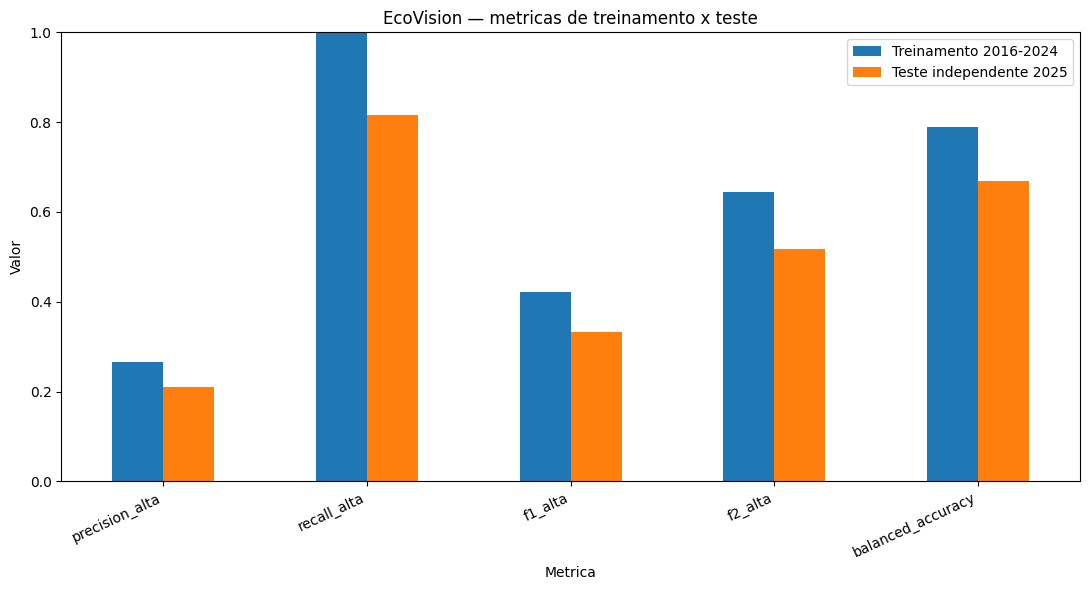

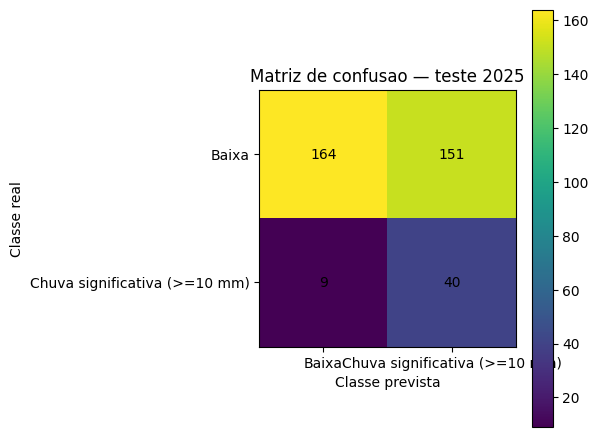

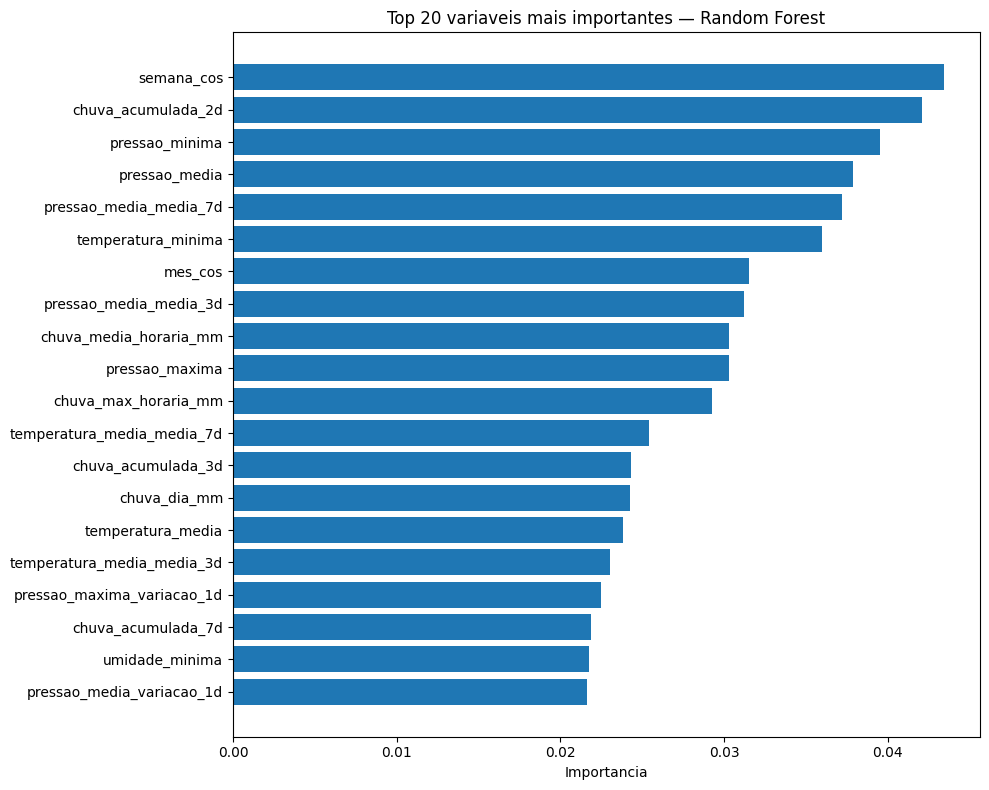


ECOVISION V8 — EXECUCAO CONCLUIDA
Modelo: Random Forest
Combinacoes avaliadas: 12
Melhores parametros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Threshold: 0.16

Metricas treino x teste:
                            n  accuracy  balanced_accuracy  precision_alta  recall_alta  f1_alta  f2_alta  f1_macro   brier  roc_auc  pr_auc  verdadeiros_positivos  falsos_positivos  falsos_negativos  verdadeiros_negativos
Treinamento 2016-2024    3247    0.6344             0.7892          0.2668       1.0000   0.4213   0.6454    0.5770  0.0588   0.9941  0.9609                    432              1187                 0                   1628
Teste independente 2025   364    0.5604             0.6685          0.2094       0.8163   0.3333   0.5168    0.5027  0.1198   0.7515  0.2656                     40               151                 9                    164

Overfitting: Diferenca entre treino e teste nao ultrapassa 0,15; avaliar junto das demais metricas

In [ ]:
# ================================================================
# ECOVISION V8 — CLASSIFICACAO BINARIA DE PRECIPITACAO
# ================================================================
#
# OBJETIVO:
#   Baixa: precipitacao D+1 < 10 mm
#   Chuva significativa: precipitacao D+1 >= 10 mm
#
# BASE:
#   bases_processadas/saida_ecovision/base_diaria_ecovision.csv
#
# FEATURES:
#   15 variaveis meteorologicas
#   6 variaveis temporais
#   3 acumulados de chuva
#   8 medias moveis
#   15 variacoes de 1 dia
#   TOTAL: 47 FEATURES
#
# VALIDACAO:
#   2016-2023: busca de hiperparametros
#   2024: selecao do threshold
#   2025: avaliacao temporal de referencia
#
# IMPORTANTE:
#   - Separacao sempre por data_alvo.
#   - classe_alvo nao e usada como feature.
#   - Nenhuma feature utiliza informacao de D+1.
#   - A base original nao e modificada.
# ================================================================


# ================================================================
# 1. INSTALACAO E IMPORTACOES
# ================================================================

import sys
import subprocess
import importlib.util

pacotes = {
    "pandas": "pandas",
    "numpy": "numpy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "joblib": "joblib",
}

for modulo, pacote in pacotes.items():
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import json
import warnings

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)


# ================================================================
# 2. CONFIGURACOES E CAMINHOS PORTAVEIS
# ================================================================

SEED = 42

LIMIAR_CHUVA = 10.0

ANOS_VALIDACAO = [2021, 2022, 2023]

ANO_AVALIACAO = 2024

ANO_TESTE = 2025

DATA_INICIO = pd.Timestamp("2016-01-01")
DATA_FIM_TESTE = pd.Timestamp("2025-12-31")

COLUNA_DATA = "data"
COLUNA_DATA_ALVO = "data_alvo"
COLUNA_ALVO_MM = "precipitacao_alvo_mm"

CLASSES = [0, 1]
NOMES_CLASSES = ["Baixa", "Chuva significativa (>=10 mm)"]


# ------------------------------------------------
# LOCALIZAR A RAIZ DO PROJETO
# ------------------------------------------------

candidatos = [
    Path("/content/EcoVision"),
    Path("/content/drive/MyDrive/EcoVision"),
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
]

PASTA_PROJETO = None

for pasta in candidatos:

    if not pasta.is_dir():
        continue

    if (
        (pasta / ".git").exists()
        or (
            (pasta / "ml").is_dir()
            and (pasta / "dados").is_dir()
        )
        or (
            (pasta / "bases_processadas").is_dir()
            and (pasta / "dados").is_dir()
        )
    ):
        PASTA_PROJETO = pasta
        break


if PASTA_PROJETO is None:

    raise FileNotFoundError(
        "Nao foi possivel identificar a raiz do projeto EcoVision.\n"
        "Clone o repositorio ou abra o notebook dentro da pasta do projeto."
    )


# ------------------------------------------------
# CAMINHO DA BASE GERADA PELA ETAPA 1
# ------------------------------------------------

CAMINHO_BASE = (
    PASTA_PROJETO
    / "bases_processadas"
    / "saida_ecovision"
    / "base_diaria_ecovision.csv"
)


# ------------------------------------------------
# PASTA DOS RESULTADOS DA MODELAGEM
# ------------------------------------------------

PASTA_SAIDA = (
    PASTA_PROJETO
    / "resultados"
    / "saida_ecovision_v8"
)

PASTA_SAIDA.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------
# VALIDACAO DOS CAMINHOS
# ------------------------------------------------

print("=" * 75)
print("ECOVISION V8 — CONFIGURACAO DO PROJETO")
print("=" * 75)

print("\nRaiz do projeto:", PASTA_PROJETO)

print("Base de entrada:", CAMINHO_BASE)

print("Pasta de resultados:", PASTA_SAIDA)

if not CAMINHO_BASE.exists():

    raise FileNotFoundError(
        "\nA base diaria nao foi encontrada.\n"
        f"Caminho esperado: {CAMINHO_BASE}\n\n"
        "Execute primeiro a Etapa 1 para construir a base diaria "
        "ou confira se o arquivo esta na pasta correta."
    )

print("\nBase diaria localizada com sucesso!")

# ================================================================
# 3. VALIDAR ARQUIVO E COLUNAS
# ================================================================

if not CAMINHO_BASE.exists():
    raise FileNotFoundError(f"Base nao encontrada: {CAMINHO_BASE}")

df = pd.read_csv(CAMINHO_BASE)

print("=" * 75)
print("ECOVISION V7 — CLASSIFICACAO BINARIA")
print("=" * 75)

print("\nDimensoes originais:", df.shape)

colunas_obrigatorias = [
    COLUNA_DATA,
    COLUNA_DATA_ALVO,
    COLUNA_ALVO_MM,
    "chuva_dia_mm",
    "chuva_max_horaria_mm",
    "chuva_media_horaria_mm",
    "temperatura_media",
    "temperatura_minima",
    "temperatura_maxima",
    "umidade_media",
    "umidade_minima",
    "umidade_maxima",
    "rajada_maxima_kmh",
    "vento_medio_kmh",
    "vento_maximo_kmh",
    "pressao_media",
    "pressao_minima",
    "pressao_maxima",
]

faltantes = [c for c in colunas_obrigatorias if c not in df.columns]

if faltantes:
    raise ValueError("Colunas obrigatorias ausentes na base:\n" + "\n".join(faltantes))


# ================================================================
# 4. CONVERSAO E AUDITORIA TEMPORAL
# ================================================================

df[COLUNA_DATA] = pd.to_datetime(df[COLUNA_DATA], errors="coerce").dt.normalize()

df[COLUNA_DATA_ALVO] = pd.to_datetime(
    df[COLUNA_DATA_ALVO], errors="coerce"
).dt.normalize()

if df[COLUNA_DATA].isna().any():
    raise ValueError("Existem datas originais invalidas.")

if df[COLUNA_DATA_ALVO].isna().any():
    raise ValueError("Existem datas-alvo invalidas.")

if df[COLUNA_DATA].duplicated().any():
    raise ValueError("Existem datas originais duplicadas.")

diferenca_dias = (df[COLUNA_DATA_ALVO] - df[COLUNA_DATA]).dt.days

if not (diferenca_dias == 1).all():
    raise ValueError("Erro temporal: data_alvo deve ser exatamente data + 1 dia.")

print("\nAUDITORIA TEMPORAL ORIGINAL")
print("Primeira data:", df[COLUNA_DATA].min())
print("Ultima data:", df[COLUNA_DATA].max())
print("Primeira data-alvo:", df[COLUNA_DATA_ALVO].min())
print("Ultima data-alvo:", df[COLUNA_DATA_ALVO].max())

print("Alinhamento D+1:", "APROVADO")


# ================================================================
# 5. DEFINIR AS 15 VARIAVEIS METEOROLOGICAS
# ================================================================

VAR_METEO = [
    "chuva_dia_mm",
    "chuva_max_horaria_mm",
    "chuva_media_horaria_mm",
    "temperatura_media",
    "temperatura_minima",
    "temperatura_maxima",
    "umidade_media",
    "umidade_minima",
    "umidade_maxima",
    "rajada_maxima_kmh",
    "vento_medio_kmh",
    "vento_maximo_kmh",
    "pressao_media",
    "pressao_minima",
    "pressao_maxima",
]

if len(VAR_METEO) != 15:
    raise AssertionError("A lista meteorologica deveria conter 15 variaveis.")

# Converter variaveis meteorologicas para numerico.
for coluna in VAR_METEO:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

# Remover sentinelas e valores infinitos.
df[VAR_METEO] = df[VAR_METEO].replace([-9999, -9999.0, np.inf, -np.inf], np.nan)

# Alvo numerico D+1.
df[COLUNA_ALVO_MM] = pd.to_numeric(df[COLUNA_ALVO_MM], errors="coerce")

df[COLUNA_ALVO_MM] = df[COLUNA_ALVO_MM].replace(
    [-9999, -9999.0, np.inf, -np.inf], np.nan
)

# Precipitacao negativa nao e um alvo valido.
df.loc[df[COLUNA_ALVO_MM] < 0, COLUNA_ALVO_MM] = np.nan


# ================================================================
# 6. PRESERVAR GRADE DIARIA COMPLETA
# ================================================================
#
# As features temporais devem ser calculadas antes de remover
# registros sem alvo valido.
#
# Isso evita que uma data sem alvo seja eliminada e faca
# o rolling ou diff saltar um dia.
# ================================================================

df = df.sort_values(COLUNA_DATA).set_index(COLUNA_DATA)

grade_completa = pd.date_range(start=df.index.min(), end=df.index.max(), freq="D")

quantidade_original = len(df)

df = df.reindex(grade_completa)

df.index.name = COLUNA_DATA

df[COLUNA_DATA_ALVO] = df.index + pd.Timedelta(days=1)

print("\nGRADE DIARIA")
print("Dias esperados:", len(grade_completa))
print("Linhas originais:", quantidade_original)
print("Dias inseridos na grade:", len(grade_completa) - quantidade_original)


# ================================================================
# 7. CRIACAO DAS 47 FEATURES
# ================================================================

features = pd.DataFrame(index=df.index)

# ------------------------------------------------
# A) 15 variaveis meteorologicas originais
# ------------------------------------------------

for coluna in VAR_METEO:
    features[coluna] = df[coluna]


# ------------------------------------------------
# B) 6 variaveis temporais
# ------------------------------------------------

features["mes"] = df.index.month

features["dia_semana"] = df.index.dayofweek

features["mes_sin"] = np.sin(2 * np.pi * df.index.month / 12)

features["mes_cos"] = np.cos(2 * np.pi * df.index.month / 12)

semana = df.index.isocalendar().week.astype(int)

features["semana_sin"] = np.sin(2 * np.pi * semana / 52.18)

features["semana_cos"] = np.cos(2 * np.pi * semana / 52.18)


# ------------------------------------------------
# C) 3 acumulados de precipitacao
# ------------------------------------------------
#
# Somente chuva observada no dia D e anteriores.
# Exigimos janela completa para evitar interpretar
# dados ausentes como acumulados completos.
# ------------------------------------------------

for janela in [2, 3, 7]:

    features[f"chuva_acumulada_{janela}d"] = (
        df["chuva_dia_mm"].rolling(window=janela, min_periods=janela).sum()
    )


# ------------------------------------------------
# D) 8 medias moveis
# ------------------------------------------------

VAR_ROLLING = ["temperatura_media", "umidade_media", "pressao_media", "vento_medio_kmh"]

for coluna in VAR_ROLLING:

    for janela in [3, 7]:

        nome = f"{coluna}_media_{janela}d"

        features[nome] = df[coluna].rolling(window=janela, min_periods=1).mean()


# ------------------------------------------------
# E) 15 variacoes de um dia
# ------------------------------------------------

for coluna in VAR_METEO:

    nome = f"{coluna}_variacao_1d"

    features[nome] = df[coluna].diff(1)


# ------------------------------------------------
# F) Conferencia das 47 features
# ------------------------------------------------

if features.shape[1] != 47:
    raise AssertionError(f"Esperadas 47 features, encontradas {features.shape[1]}.")

if features.columns.duplicated().any():
    raise AssertionError("Existem nomes de features duplicados.")

print("\nFEATURES CRIADAS")
print("Meteorologicas:", 15)
print("Temporais:", 6)
print("Acumulados de chuva:", 3)
print("Medias moveis:", 8)
print("Variacoes de 1 dia:", 15)
print("TOTAL:", features.shape[1])

# Auditoria das features.
auditoria_features = pd.DataFrame(
    {
        "feature": features.columns,
        "valores_validos": [features[c].notna().sum() for c in features.columns],
        "valores_ausentes": [features[c].isna().sum() for c in features.columns],
        "percentual_ausente": [
            features[c].isna().mean() * 100 for c in features.columns
        ],
    }
)

auditoria_features.to_csv(PASTA_SAIDA / "auditoria_features_v7.csv", index=False)

features = features.replace([np.inf, -np.inf], np.nan)


# ================================================================
# 8. CONSTRUIR ALVO BINARIO
# ================================================================
#
# 0 = Baixa: precipitacao < 10 mm
# 1 = Alta:  precipitacao >= 10 mm
#
# A coluna classe_alvo original nao e utilizada.
# ================================================================

precipitacao_alvo = df[COLUNA_ALVO_MM]

alvo_binario = pd.Series(
    np.where(
        precipitacao_alvo.notna(),
        (precipitacao_alvo >= LIMIAR_CHUVA).astype(float),
        np.nan,
    ),
    index=df.index,
    name="alvo_binario",
)

# Construir tabela final.
base_modelagem = features.copy()

base_modelagem["data"] = base_modelagem.index

base_modelagem["data_alvo"] = base_modelagem.index + pd.Timedelta(days=1)

base_modelagem["precipitacao_alvo_mm"] = precipitacao_alvo

base_modelagem["alvo_binario"] = alvo_binario

# Apenas alvos de 2016 a 2025.
base_modelagem = base_modelagem[
    base_modelagem["data_alvo"].between(
        pd.Timestamp("2016-01-01"), pd.Timestamp("2025-12-31")
    )
].copy()

# Excluir somente alvos sem valor valido.
base_modelagem = base_modelagem[base_modelagem["alvo_binario"].notna()].copy()

base_modelagem["alvo_binario"] = base_modelagem["alvo_binario"].astype(int)

base_modelagem["ano_alvo"] = base_modelagem["data_alvo"].dt.year

X_COLS = features.columns.tolist()

X = base_modelagem[X_COLS].copy()

y = base_modelagem["alvo_binario"].copy()

print("\nBASE DE MODELAGEM")
print("Dimensoes:", base_modelagem.shape)
print("Exemplos validos:", len(base_modelagem))
print("\nDistribuicao binaria:")
print(y.value_counts().rename(index={0: "Baixa", 1: "Alta"}))

print("\nDistribuicao percentual:")
print(
    (y.value_counts(normalize=True) * 100)
    .rename(index={0: "Baixa", 1: "Alta"})
    .round(2)
)


# ================================================================
# ================================================================
# 9. MODELO E BUSCA DE HIPERPARAMETROS
# ================================================================
# Random Forest foi escolhido por lidar bem com relacoes nao lineares,
# interacoes entre variaveis meteorologicas e dados tabulares. Tambem
# permite analisar importancia das features e nao exige normalizacao.
# A imputacao fica dentro do Pipeline para evitar vazamento entre folds.

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, ParameterGrid
from sklearn.metrics import make_scorer

# A busca usa somente alvos de 2016 a 2023. 2024 fica reservado para
# calibrar o limiar de decisao; 2025 permanece como teste intocado.
DATA_CORTE_BUSCA = pd.Timestamp("2024-01-01")
mascara_busca = base_modelagem["data_alvo"] < DATA_CORTE_BUSCA
X_busca = X.loc[mascara_busca].copy()
y_busca = y.loc[mascara_busca].copy()

if y_busca.nunique() != 2:
    raise ValueError("A base de busca precisa conter as duas classes.")

pipeline_rf = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "modelo",
            RandomForestClassifier(
                class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
            ),
        ),
    ]
)

# 2 x 3 x 2 = 12 combinacoes distintas de tres hiperparametros.
param_grid = {
    "modelo__n_estimators": [200, 400],
    "modelo__max_depth": [None, 12, 20],
    "modelo__min_samples_leaf": [2, 5],
}
combinacoes = list(ParameterGrid(param_grid))
assert len(combinacoes) >= 10

# Como as linhas ja estao ordenadas cronologicamente, cada fold valida
# em um bloco posterior ao bloco usado para treinar.
cv_temporal = TimeSeriesSplit(n_splits=3)

busca = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_temporal,
    refit=True,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

print("\nBUSCA DE HIPERPARAMETROS")
print("Registros usados (2016-2023):", len(X_busca))
print("Combinacoes testadas:", len(combinacoes))
print("Validacao cruzada: TimeSeriesSplit com 3 folds")
print("2024 e 2025 estao fora da busca.")

busca.fit(X_busca, y_busca)

melhor_modelo_cv = busca.best_estimator_
melhores_parametros = busca.best_params_

resultados_busca = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score")
resultados_busca.to_csv(PASTA_SAIDA / "resultados_gridsearch_v8.csv", index=False)

print("\nMelhores parametros:")
print(melhores_parametros)
print("Melhor F1 medio na CV:", round(busca.best_score_, 4))

# ================================================================
# 10. FUNCOES DE METRICAS E LIMIAR
# ================================================================


def calcular_metricas(y_real, probabilidade, threshold=0.5):
    y_real = np.asarray(y_real).astype(int)
    probabilidade = np.asarray(probabilidade, dtype=float)
    previsao = (probabilidade >= threshold).astype(int)
    cm = confusion_matrix(y_real, previsao, labels=CLASSES)
    metricas = {
        "n": int(len(y_real)),
        "accuracy": accuracy_score(y_real, previsao),
        "balanced_accuracy": balanced_accuracy_score(y_real, previsao),
        "precision_alta": precision_score(
            y_real, previsao, pos_label=1, zero_division=0
        ),
        "recall_alta": recall_score(y_real, previsao, pos_label=1, zero_division=0),
        "f1_alta": f1_score(y_real, previsao, pos_label=1, zero_division=0),
        "f2_alta": fbeta_score(y_real, previsao, beta=2, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_real, previsao, average="macro", zero_division=0),
        "brier": brier_score_loss(y_real, probabilidade),
        "roc_auc": (
            roc_auc_score(y_real, probabilidade)
            if len(np.unique(y_real)) == 2
            else np.nan
        ),
        "pr_auc": (
            average_precision_score(y_real, probabilidade)
            if len(np.unique(y_real)) == 2
            else np.nan
        ),
        "verdadeiros_positivos": int(cm[1, 1]),
        "falsos_positivos": int(cm[0, 1]),
        "falsos_negativos": int(cm[1, 0]),
        "verdadeiros_negativos": int(cm[0, 0]),
    }
    return metricas, previsao, cm


def selecionar_threshold(y_real, probabilidade):
    # Selecionado apenas na validacao de 2024; favorece recall da classe
    # de chuva alta, mas F2 considera tambem a precisao.
    linhas = []
    for t in np.arange(0.10, 0.901, 0.01):
        pred = (np.asarray(probabilidade) >= t).astype(int)
        linhas.append(
            {
                "threshold": float(t),
                "f2_alta": fbeta_score(
                    y_real, pred, beta=2, pos_label=1, zero_division=0
                ),
                "precision_alta": precision_score(
                    y_real, pred, pos_label=1, zero_division=0
                ),
                "recall_alta": recall_score(y_real, pred, pos_label=1, zero_division=0),
            }
        )
    tabela = pd.DataFrame(linhas).sort_values(
        ["f2_alta", "precision_alta", "threshold"], ascending=[False, False, False]
    )
    return float(tabela.iloc[0]["threshold"]), tabela


# ================================================================
# 11. VALIDACAO EM 2024 E DEFINICAO DO THRESHOLD
# ================================================================

inicio_2024 = pd.Timestamp("2024-01-01")
fim_2024 = pd.Timestamp("2024-12-31")
mascara_2024 = base_modelagem["data_alvo"].between(inicio_2024, fim_2024)
X_2024, y_2024 = X.loc[mascara_2024], y.loc[mascara_2024]

if len(X_2024) == 0:
    raise ValueError("Nao ha dados de validacao para 2024.")

# O melhor estimador foi ajustado pela busca em dados ate 2023.
prob_2024 = melhor_modelo_cv.predict_proba(X_2024)[:, 1]
melhor_threshold, tabela_threshold = selecionar_threshold(y_2024.to_numpy(), prob_2024)
tabela_threshold.to_csv(PASTA_SAIDA / "busca_threshold_2024_v8.csv", index=False)
metricas_2024, previsoes_2024, cm_2024 = calcular_metricas(
    y_2024.to_numpy(), prob_2024, melhor_threshold
)

print("\nVALIDACAO 2024")
print("Threshold selecionado:", round(melhor_threshold, 3))
print(pd.Series(metricas_2024).to_string())
print("Matriz de confusao 2024:\n", cm_2024)

# ================================================================
# 12. TREINAMENTO FINAL ATE 2024 E TESTE INDEPENDENTE 2025
# ================================================================

inicio_2025 = pd.Timestamp("2025-01-01")
fim_2025 = pd.Timestamp("2025-12-31")
mascara_treino_final = base_modelagem["data_alvo"] < inicio_2025
mascara_teste_2025 = base_modelagem["data_alvo"].between(inicio_2025, fim_2025)

X_treino_final, y_treino_final = (
    X.loc[mascara_treino_final],
    y.loc[mascara_treino_final],
)
X_teste, y_teste = X.loc[mascara_teste_2025], y.loc[mascara_teste_2025]

if len(X_teste) == 0:
    raise ValueError("Nao ha dados de teste em 2025.")
if y_treino_final.nunique() != 2 or y_teste.nunique() != 2:
    raise ValueError("Treino final e teste precisam conter as duas classes.")

# Recria o modelo com os melhores hiperparametros e treina em 2016-2024.
modelo_final = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=melhores_parametros["modelo__n_estimators"],
                max_depth=melhores_parametros["modelo__max_depth"],
                min_samples_leaf=melhores_parametros["modelo__min_samples_leaf"],
                class_weight="balanced_subsample",
                random_state=SEED,
                n_jobs=-1,
            ),
        ),
    ]
)
modelo_final.fit(X_treino_final, y_treino_final)

# Metricas de treino (in-sample) e teste com o MESMO threshold.
prob_treino = modelo_final.predict_proba(X_treino_final)[:, 1]
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]
metricas_treino, previsoes_treino, cm_treino = calcular_metricas(
    y_treino_final.to_numpy(), prob_treino, melhor_threshold
)
metricas_2025, previsoes_2025, cm_2025 = calcular_metricas(
    y_teste.to_numpy(), prob_teste, melhor_threshold
)

comparacao_treino_teste = pd.DataFrame(
    [metricas_treino, metricas_2025],
    index=["Treinamento 2016-2024", "Teste independente 2025"],
)
comparacao_treino_teste.to_csv(PASTA_SAIDA / "metricas_treino_vs_teste_v8.csv")
print("\nCOMPARACAO TREINAMENTO X TESTE")
print(comparacao_treino_teste.round(4).to_string())
print("\nMatriz de confusao 2025:\n", cm_2025)
print("\nRelatorio de classificacao 2025:")
print(
    classification_report(
        y_teste,
        previsoes_2025,
        labels=CLASSES,
        target_names=NOMES_CLASSES,
        zero_division=0,
    )
)

# Diferenca entre F1 de treino e teste como indicador simples de overfitting.
diferenca_f1 = metricas_treino["f1_alta"] - metricas_2025["f1_alta"]
if diferenca_f1 > 0.15:
    diagnostico_overfitting = (
        "Diferenca elevada entre treino e teste; ha indicio de overfitting."
    )
else:
    diagnostico_overfitting = "Diferenca entre treino e teste nao ultrapassa 0,15; avaliar junto das demais metricas."

# ================================================================
# 13. SALVAR PREVISOES, AUDITORIA E GRAFICOS
# ================================================================

previsoes_2025_df = pd.DataFrame(
    {
        "data_alvo": base_modelagem.loc[mascara_teste_2025, "data_alvo"].values,
        "precipitacao_real_mm": base_modelagem.loc[
            mascara_teste_2025, "precipitacao_alvo_mm"
        ].values,
        "classe_real": y_teste.values,
        "probabilidade_alta": prob_teste,
        "classe_prevista": previsoes_2025,
        "resultado": np.where(previsoes_2025 == y_teste.to_numpy(), "Acerto", "Erro"),
    }
)
previsoes_2025_df.to_csv(PASTA_SAIDA / "previsoes_2025_v8.csv", index=False)

# Grafico de metricas: comparacao lado a lado.
metricas_grafico = comparacao_treino_teste[
    ["precision_alta", "recall_alta", "f1_alta", "f2_alta", "balanced_accuracy"]
]
ax = metricas_grafico.T.plot(kind="bar", figsize=(11, 6))
ax.set_title("EcoVision — metricas de treinamento x teste")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.set_xlabel("Metrica")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "metricas_treino_vs_teste_v8.png", dpi=160)
plt.show()

# Matriz de confusao do teste.
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_2025, interpolation="nearest")
ax.set_title("Matriz de confusao — teste 2025")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_xticks([0, 1], NOMES_CLASSES)
ax.set_yticks([0, 1], NOMES_CLASSES)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_2025[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "matriz_confusao_2025_v8.png", dpi=160)
plt.show()

# Curva de importancia das variaveis.
importancia_df = pd.DataFrame(
    {
        "feature": X_COLS,
        "importancia": modelo_final.named_steps["modelo"].feature_importances_,
    }
).sort_values("importancia", ascending=False)
importancia_df.to_csv(PASTA_SAIDA / "importancia_features_v8.csv", index=False)
top = importancia_df.head(20).sort_values("importancia")
plt.figure(figsize=(10, 8))
plt.barh(top["feature"], top["importancia"])
plt.title("Top 20 variaveis mais importantes — Random Forest")
plt.xlabel("Importancia")
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "importancia_features_v8.png", dpi=160)
plt.show()

# ================================================================
# 14. SALVAR MODELO, CONFIGURACAO E RELATORIO MARKDOWN
# ================================================================

joblib.dump(modelo_final, PASTA_SAIDA / "modelo_ecovision_v8.joblib")

configuracao = {
    "versao": "EcoVision V8",
    "problema": "Classificar precipitacao do dia seguinte (D+1): baixa < 10 mm; alta >= 10 mm",
    "modelo": "RandomForestClassifier",
    "justificativa_modelo": "Modelo de ensemble adequado a dados tabulares e relacoes nao lineares; permite importancia de features.",
    "features": X_COLS,
    "quantidade_features": len(X_COLS),
    "hiperparametros_selecionados": melhores_parametros,
    "combinacoes_testadas": len(combinacoes),
    "validacao_cruzada": "TimeSeriesSplit(n_splits=3), somente dados com data_alvo anterior a 2024",
    "threshold": melhor_threshold,
    "metricas_treinamento": {k: float(v) for k, v in metricas_treino.items()},
    "metricas_teste_2025": {k: float(v) for k, v in metricas_2025.items()},
    "diagnostico_overfitting": diagnostico_overfitting,
    "periodo_treino_final": "2016-01-01 a 2024-12-31",
    "periodo_teste": "2025-01-01 a 2025-12-31",
    "observacoes": [
        "2025 nao foi usado na busca de hiperparametros nem na selecao do threshold.",
        "Imputacao mediana executada dentro do Pipeline.",
        "A divisao foi temporal por data_alvo.",
        "Metricas de treinamento sao in-sample e devem ser comparadas com o teste para investigar overfitting.",
    ],
}
with open(PASTA_SAIDA / "configuracao_v8.json", "w", encoding="utf-8") as f:
    json.dump(configuracao, f, ensure_ascii=False, indent=2)

# Relatorio com resultados reais gerados na execucao. Fonte, estacao e
# municipio devem ser preenchidos com os metadados reais da base INMET.
relatorio_md = f"""# Relatorio de Inteligencia Artificial e Machine Learning — EcoVision V8

## 1. Problema e objetivo
O EcoVision realiza uma classificacao binaria da precipitacao do dia seguinte (D+1). A classe **Baixa** representa acumulado inferior a 10 mm; a classe **Alta** representa acumulado igual ou superior a 10 mm. O objetivo e apoiar o planejamento preventivo e a comunicacao de risco, sem substituir alertas oficiais ou a Defesa Civil.

## 2. Dados e preparacao
- Fonte dos dados: INMET (informar link oficial, nome/codigo da estacao e municipio no README do repositorio).
- Periodo de alvos: 2016 a 2025.
- Amostras de treinamento final: {len(X_treino_final)}.
- Amostras de teste independente: {len(X_teste)}.
- Variaveis preditoras: {len(X_COLS)}.
- Alvo: precipitacao observada em D+1, convertida em classes pelo limite de 10 mm.
- Valores invalidos/sentinelas sao convertidos em ausentes; imputacao pela mediana ocorre dentro do Pipeline.
- Features temporais, acumulados, medias moveis e diferencas sao calculados com dados do dia D e anteriores.

## 3. Modelo e estrategia de validacao
Foi utilizado Random Forest por ser um ensemble de arvores apropriado para dados tabulares, capaz de capturar relacoes nao lineares e interacoes entre variaveis, sem exigir padronizacao. Foram testadas **{len(combinacoes)} combinacoes** de tres hiperparametros (n_estimators, max_depth e min_samples_leaf). A selecao ocorreu por GridSearchCV com TimeSeriesSplit de 3 folds, usando somente dados com data_alvo anterior a 2024. O ano de 2024 foi reservado para escolher o threshold; 2025 foi mantido como teste independente.

Melhores hiperparametros: `{json.dumps(melhores_parametros, ensure_ascii=False)}`. Melhor F1 medio na validacao cruzada: {busca.best_score_:.4f}. Threshold selecionado em 2024: {melhor_threshold:.2f}.

## 4. Resultados: treinamento x teste
{comparacao_treino_teste.round(4).to_markdown()}

### Diagnostico de overfitting
{diagnostico_overfitting} A metrica de treinamento e calculada sobre os mesmos exemplos usados no ajuste (in-sample), portanto tende a ser otimista. A avaliacao mais representativa da generalizacao e o teste temporal de 2025.

### Matriz de confusao — teste 2025
`[[VN, FP], [FN, VP]] = {cm_2025.tolist()}`.

## 5. Interpretacao para o cidadao
O modelo tenta sinalizar com antecedencia de um dia a possibilidade de acumulado de chuva de pelo menos 10 mm. Se apresentar recall baixo para a classe Alta, podera deixar de sinalizar dias chuvosos; se a precisao for baixa, podera gerar alertas desnecessarios. Por isso, a escolha entre reduzir falsos negativos e evitar falsos positivos deve considerar o uso publico pretendido. O resultado e experimental e depende da cobertura e qualidade da estacao meteorologica utilizada. Nao deve ser tratado como previsao oficial, alerta de inundacao ou orientacao de emergencia.

## 6. Limitacoes e proximos passos
A avaliacao usa dados de uma base/estacao especifica e nao garante desempenho em outros municipios. E necessario registrar no repositorio a identificacao da estacao, localidade, URL de origem, data de coleta e eventuais lacunas. Proximos passos incluem testar outras estacoes, avaliar calibracao das probabilidades e validar o modelo em periodos futuros.

## 7. Arquivos gerados
- `resultados_gridsearch_v8.csv`: resultados das combinacoes e folds.
- `metricas_treino_vs_teste_v8.csv` e `.png`: comparacao de metricas.
- `matriz_confusao_2025_v8.png`: erros e acertos no teste.
- `importancia_features_v8.csv` e `.png`: importancia das variaveis.
- `previsoes_2025_v8.csv`: previsoes individuais do teste.
- `modelo_ecovision_v8.joblib`: modelo final treinado.

> Antes da entrega, complete no README a URL oficial do conjunto INMET, codigo/nome da estacao, municipio/UF, periodo efetivamente disponivel e quantidade de registros validos. Nao invente esses metadados.
"""
(PASTA_SAIDA / "RELATORIO_ML.md").write_text(relatorio_md, encoding="utf-8")

# Dependencias reproduziveis.
(PASTA_SAIDA / "requirements.txt").write_text(
    "pandas\nnumpy\nscikit-learn\nmatplotlib\njoblib\ntabulate\n", encoding="utf-8"
)

print("\n" + "=" * 72)
print("ECOVISION V8 — EXECUCAO CONCLUIDA")
print("Modelo: Random Forest")
print("Combinacoes avaliadas:", len(combinacoes))
print("Melhores parametros:", melhores_parametros)
print("Threshold:", round(melhor_threshold, 3))
print("\nMetricas treino x teste:")
print(comparacao_treino_teste.round(4).to_string())
print("\nOverfitting:", diagnostico_overfitting)
print("\nArquivos salvos em:", PASTA_SAIDA)